# 17 - Linear systems and the eigenvalue method

**MATH 331 - Differential Equations.** Lecture plan: Session 17 (Sections 2-4) and Session 18
(Sections 5-7), Unit 8: linear systems and the eigenvalue method.

**References:** J. Lebl, *Notes on Diffy Qs*, Sections 3.1-3.4 and 3.6-3.8, and exercises from the list
at the end of Chapter 3; notebooks 04, 06, 07, 08, 16; videos R05, R07, R08, R09.

**What you will learn**
1. Two tanks, and every linear equation of order $n$ with constant coefficients, are systems
   $\vec{x}\,' = A\vec{x}$; two carts are $\vec{x}\,'' = A\vec{x}$, or $\vec{x}\,' = A\vec{x}$ with four
   unknowns.
2. To solve them by eigenvalues and eigenvectors, in the cases of notebook 06 (a repeated eigenvalue
   splits in two).
3. The fundamental matrix, and the matrix exponential $e^{tA}$ that checks every result.

## 1. Theory in brief

**A system.** $\vec{x}\,' = A\vec{x}$: the unknown is a vector $\vec{x}(t) = (x_1(t), x_2(t), \dots)$, $A$ a
constant matrix; $\vec{x}\,' = (x_1', x_2', \dots)$, and row $k$ of $A\vec{x}$ is the right-hand side of
$x_k'$.

**Eigenvalues.** $A\vec{v} = \lambda\vec{v}$ with $\vec{v} \ne \vec{0}$: $A$ only stretches $\vec{v}$, by the
factor $\lambda$. (Notebook 16 used the same word for the special values of $\lambda$ in
$x'' + \lambda x = 0$: the same idea, with a function in place of $\vec{v}$.) The eigenvalues solve
$\det(A - \lambda I) = 0$. ($I$ is the identity matrix: 1 on the diagonal, 0 elsewhere, so
$I\vec{v} = \vec{v}$ and $A - \lambda I$ is $A$ with $\lambda$ subtracted from each diagonal entry.) For a
$2 \times 2$ matrix with
rows $(a_{11}, a_{12})$, $(a_{21}, a_{22})$ ($a_{ij}$ is in row $i$, column $j$):
$\det(A - \lambda I) = (a_{11} - \lambda)(a_{22} - \lambda) - a_{12}a_{21}
= \lambda^2 - (a_{11} + a_{22})\lambda + (a_{11}a_{22} - a_{12}a_{21})$; $a_{11} + a_{22}$ is the **trace**
(the sum of the diagonal), $a_{11}a_{22} - a_{12}a_{21}$ the **determinant**.

**The method.** $\vec{x} = \vec{v}\,e^{\lambda t}$ is a solution exactly when $A\vec{v} = \lambda\vec{v}$.

| Eigenvalues of a $2 \times 2$ matrix | Two real solutions |
|---|---|
| real, $\lambda_1 \ne \lambda_2$ | $\vec{v}_1e^{\lambda_1t}$, $\ \vec{v}_2e^{\lambda_2t}$ |
| complex pair $\alpha \pm i\beta$ | real and imaginary parts of $\vec{v}\,e^{(\alpha + i\beta)t}$ |
| $\lambda$ twice, $A = \lambda I$ | $(1, 0)e^{\lambda t}$, $(0, 1)e^{\lambda t}$ |
| $\lambda$ twice, one eigenvector | $\vec{v}e^{\lambda t}$, $(\vec{w} + \vec{v}t)e^{\lambda t}$ (see below) |

In the last row $\vec{v}$ is an eigenvector and $\vec{w}$ a **generalized eigenvector**:
$(A - \lambda I)\vec{w} = \vec{v}$.

**Constants.** $\vec{x} = C_1\vec{x}_1 + C_2\vec{x}_2$. Two independent solutions, written as columns side
by side, form a **fundamental matrix** $X(t)$ (any two independent ones); the constants
$C = (C_1, C_2)$ solve the linear system $X(0)\,C = \vec{x}(0)$ (notebook 08, video R08). In every case
$\vec{x}(t) = e^{tA}\vec{x}(0)$ (Lebl, Theorem 3.8.1), where, as $e^{at} = 1 + at + \frac{(at)^2}{2} + \dots$
(video R09), $e^{tA} = I + tA + \frac{t^2A^2}{2} + \dots$. It is also $X(t)\,X(0)^{-1}$ (Lebl, Section 3.8.4),
$X(0)^{-1}$ being the matrix that undoes $X(0)$; SciPy's `expm(t * A)` computes it.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: companion_matrix, two_by_two_case, eigen_solution, rk4, check, check_vector, check_formula).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                      # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. Eigenvalues and eigenvectors: a refresher

*Lebl, Example 3.4.1.* The matrix with rows $(2, 1)$, $(0, 1)$ sends $(1, 0)$ to $(2, 0) = 2\,(1, 0)$: the
eigenvalue 2, the eigenvector $(1, 0)$.

*Lebl, Examples 3.4.2-3.4.3.* For $A = \begin{pmatrix} 2 & 1 & 1 \\ 1 & 2 & 0 \\ 0 & 0 & 2 \end{pmatrix}$, the
last row of $A - \lambda I$ is $(0, 0, 2 - \lambda)$, so (expanding along it, video R07) the determinant is
$2 - \lambda$ times the determinant of the top-left $2 \times 2$ block, $(2 - \lambda)^2 - 1$: the eigenvalues
are 1, 2, 3. For 3, $A - 3I$ has rows $(-1, 1, 1)$, $(1, -1, 0)$, $(0, 0, -1)$: the third row of
$(A - 3I)\vec{v} = \vec{0}$ says $v_3 = 0$, the second $v_1 = v_2$, so $\vec{v} = (1, 1, 0)$.

**Triangular matrices.** When every entry below the diagonal is 0 (as in Example 3.4.1),
$\det(A - \lambda I)$ is the product of the diagonal entries of $A - \lambda I$,
$(a_{11} - \lambda)(a_{22} - \lambda)\cdots$: the eigenvalues are the diagonal entries.

**Are eigenvectors unique?** No: every nonzero multiple is one (a complex multiple too, when
$\lambda$ is complex). `np.linalg.eig` gives $(0.707, 0.707, 0)$: the same direction, length 1.

**The $2 \times 2$ shortcut.** The first row of $(A - \lambda I)\vec{v} = \vec{0}$ is
$(a_{11} - \lambda)v_1 + a_{12}v_2 = 0$, solved by $\vec{v} = (a_{12},\ \lambda - a_{11})$; the second
row then holds too: $\det(A - \lambda I) = 0$ means that the two rows are multiples of each other. If that
vector is zero, take $(\lambda - a_{22},\ a_{21})$ from the second row (`ol.two_by_two_case` takes the
longer of the two). For Lebl's $\begin{pmatrix} 1 & 2 \\ 2 & 1 \end{pmatrix}$ (trace 2, determinant $-3$):
$\lambda^2 - 2\lambda - 3 = 0$, $\lambda = -1$ and 3; the shortcut gives $(2, -2)$ and $(2, 2)$.

In [2]:
lam = sp.symbols("lambda")
t = sp.symbols("t", real=True)


def describe(case):
    # the eigenvalues found by ol.two_by_two_case, as a student writes them
    first, second = case.eigenvalues
    if case.case == ol.CASE_COMPLEX:
        return f"{first.real:.3g} +- {first.imag:.3g}i"
    if first == second:
        return f"{first:.3g} (twice)"
    return f"{first:.3g} and {second:.3g}"


def report(name, case):
    # what ol.two_by_two_case found, in one line
    vectors = [np.round(vector, 6).tolist() for vector in case.eigenvectors]
    extra = "" if case.generalized is None else f"; generalized eigenvector w = {case.generalized.tolist()}"
    print(f"{name}: {case.case}; trace {case.trace:g}, determinant {case.determinant:g}; "
          f"eigenvalues {describe(case)}; eigenvectors {vectors}{extra}")


ONE_LINE = np.array([[2, 1], [0, 1]])                    # Lebl, Example 3.4.1
assert np.array_equal(ONE_LINE @ [1, 0], 2 * np.array([1, 0]))                       # the values of the book

REFRESHER = sp.Matrix([[2, 1, 1], [1, 2, 0], [0, 0, 2]])  # Lebl, Examples 3.4.2 and 3.4.3
print("det(A - lambda I) =", sp.factor((REFRESHER - lam * sp.eye(3)).det()))
# eigenvects() gives triples (eigenvalue, how many times, [eigenvectors]); keep value: vectors
found = {value: [list(vector) for vector in vectors] for value, times_, vectors in REFRESHER.eigenvects()}
for value, vectors in found.items():
    print(f"SymPy: eigenvalue {value}, eigenvector {vectors[0]}")
assert sorted(found) == [1, 2, 3] and found[3] == [[1, 1, 0]]                       # the values of the book

# np.linalg.eig gives the eigenvalues and a matrix whose COLUMNS are the eigenvectors
values, vectors = np.linalg.eig(np.array(REFRESHER, dtype=float))
# NumPy works with complex numbers; .real and .imag are the two parts (here all imaginary parts are 0)
assert np.allclose(values.imag, 0.0) and np.allclose(vectors.imag, 0.0)
unit = vectors[:, np.argmax(values.real)].real      # column number k is vectors[:, k]: the one of 3
print("np.linalg.eig, the eigenvector for 3:", np.round(unit, 3),
      " length", round(np.linalg.norm(unit), 12))  # norm = the length of the vector
assert np.allclose(unit / unit[0], [1, 1, 0])                                        # the same direction

EXAMPLE_381 = [[1, 2], [2, 1]]                           # Lebl, Example 3.8.1
case_381 = ol.two_by_two_case(EXAMPLE_381)               # what you compute by hand, in one object
report("[[1, 2], [2, 1]]", case_381)

det(A - lambda I) = -(lambda - 3)*(lambda - 2)*(lambda - 1)
SymPy: eigenvalue 1, eigenvector [-1, 1, 0]
SymPy: eigenvalue 2, eigenvector [0, -1, 1]
SymPy: eigenvalue 3, eigenvector [1, 1, 0]
np.linalg.eig, the eigenvector for 3: [0.707 0.707 0.   ]  length 1.0
[[1, 2], [2, 1]]: real distinct; trace 2, determinant -3; eigenvalues -1 and 3; eigenvectors [[2.0, -2.0], [2.0, 2.0]]


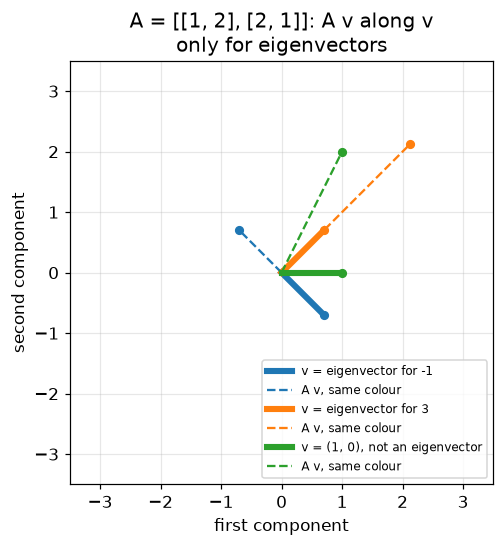

In [3]:
# drawing code: you can skip reading it
FIGURE_SIZE = (8.0, 3.6)                # every figure is drawn at the width it is shown
SQUARE_FIGURE = (5.0, 5.0)
SQUARE = (-3.5, 3.5)                    # the window of the picture of vectors
OTHER = np.array([1.0, 0.0])            # a vector that is not an eigenvector

matrix_381 = np.array(EXAMPLE_381, dtype=float)
fig, ax = plt.subplots(figsize=SQUARE_FIGURE)
pictures = [(vector / np.linalg.norm(vector), f"eigenvector for {value:g}")
            for value, vector in zip(case_381.eigenvalues, case_381.eigenvectors)]
pictures.append((OTHER, "(1, 0), not an eigenvector"))
for (vector, name), colour in zip(pictures, ("C0", "C1", "C2")):
    image = matrix_381 @ vector
    ax.plot([0.0, vector[0]], [0.0, vector[1]], "-", color=colour, linewidth=4, label=f"v = {name}")
    ax.plot([0.0, image[0]], [0.0, image[1]], "--", color=colour, linewidth=1.5, label="A v, same colour")
    ax.plot(*np.column_stack([vector, image]), "o", color=colour, markersize=5)
ax.set_xlim(*SQUARE)
ax.set_ylim(*SQUARE)
ax.set_aspect("equal")
ax.set_xlabel("first component")
ax.set_ylabel("second component")
ax.set_title("A = [[1, 2], [2, 1]]: A v along v\nonly for eigenvectors")
ax.legend(loc="lower right", fontsize=8)
plt.show()

*The plot shows* three vectors of length 1 (thick) and their images $A\vec{v}$ (dashed, in the colour of
their vector): along $(1, 1)$ three times longer, along $(1, -1)$ reversed, both on their own lines;
$(1, 0)$ goes off its line, to $(1, 2)$.

## 3. An equation of order $n$ as a system

Take $a_ny^{(n)} + \dots + a_1y' + a_0y = 0$, $a_n \ne 0$ (notebook 16's letters, $t$ for $x$), and the
unknowns $u_1 = y$, $u_2 = y'$, ..., $u_n = y^{(n-1)}$ (Lebl, (3.1.8), there for any equation). Then
$u_1' = u_2$, ..., $u_{n-1}' = u_n$, and the equation, solved for $y^{(n)}$, gives
$u_n' = -(a_0u_1 + \dots + a_{n-1}u_n)/a_n$: a system $\vec{u}\,' = A\vec{u}$ (`ol.companion_matrix`).

**Theorem (the theory exercise of Session 17).** The solutions of the equation with $y(t_0), \dots,
y^{(n-1)}(t_0)$ given and those of the system with $\vec{u}(t_0) = (y(t_0), \dots, y^{(n-1)}(t_0))$
correspond one to one: $y$ gives $\vec{u} = (y, y', \dots, y^{(n-1)})$, and $\vec{u}$ gives $y = u_1$.

*Proof.*
* If $y$ solves the equation, put $u_k = y^{(k-1)}$. Then $u_k' = y^{(k)} = u_{k+1}$ for $k < n$, and
  $u_n' = y^{(n)}$, which the equation gives as the last row. So $\vec{u}$ solves the system.
* If $\vec{u}$ solves the system, put $y = u_1$. The first $n - 1$ rows give, one after the other,
  $u_2 = y'$, ..., $u_n = y^{(n-1)}$; then the last row, times $a_n$, is the equation for $y$.
* The initial values match by the definition of $\vec{u}$. $\blacksquare$

The same change works for any equation, linear or not, and for several: each equation of order $n$
brings $n$ unknowns. So Picard's theorem for systems (Lebl, Theorem 3.1.1) covers equations of order $n$.
And $\det(\lambda I - A) = (a_n\lambda^n + \dots + a_0)/a_n$ (it differs from $\det(A - \lambda I)$ at most by
its sign, so it has the same roots): **the eigenvalues of $A$ are the roots $r$ of the characteristic
equation** (notebook 06; checked below for $n = 3$).

Example 3.1.4:
 [[0. 1. 0.]
 [0. 0. 1.]
 [1. 8. 2.]]
its eigenvalues: [-1.  1.  3.] = the roots of notebook 16
y(1): rk4 on the system 7.64770, higher_order_solution 7.64770, largest difference 9.9e-08


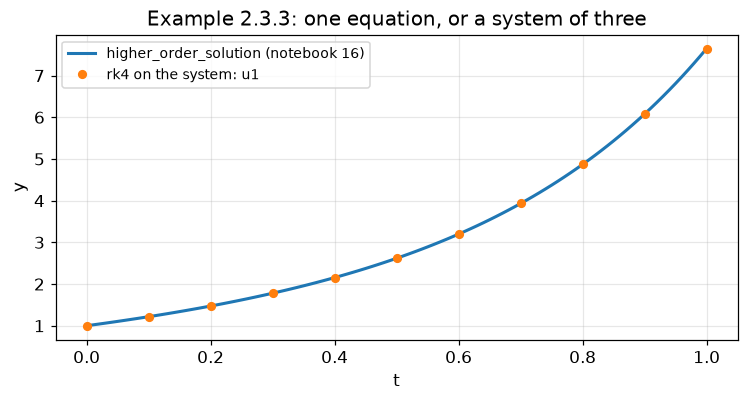

In [4]:
a3, a2, a1, a0 = sp.symbols("a3 a2 a1 a0", nonzero=True)
general = sp.Matrix([[0, 1, 0], [0, 0, 1], [-a0 / a3, -a1 / a3, -a2 / a3]])           # the matrix for n = 3
characteristic = (a3 * lam ** 3 + a2 * lam ** 2 + a1 * lam + a0) / a3
# charpoly = det(lambda I - A), as a polynomial in lambda
assert sp.simplify(general.charpoly(lam).as_expr() - characteristic) == 0

# Lebl, Example 3.1.4: x''' = 2x'' + 8x' + x + t, with u1 = x, u2 = x', u3 = x''; the matrix holds the
# part without t. The coefficients a3, a2, a1, a0 come highest derivative first (notebook 16), with the
# signs of x''' - 2x'' - 8x' - x = t.
EXAMPLE_314 = (1, -2, -8, -1)
matrix_314 = ol.companion_matrix(EXAMPLE_314)
print("Example 3.1.4:\n", matrix_314)
assert np.array_equal(matrix_314, [[0, 1, 0], [0, 0, 1], [1, 8, 2]])                  # the values of the book

EXAMPLE_233 = (1, -3, -1, 3)               # notebook 16, Lebl Example 2.3.3: y''' - 3y'' - y' + 3y = 0
START_233 = (1.0, 2.0, 3.0)                # y(0), y'(0), y''(0)
STEP = 0.01
T_ONE = 1.0
MARK_EVERY = 10
N_POINTS = 400                             # points of a curve
system_233 = ol.companion_matrix(EXAMPLE_233)
print("its eigenvalues:", np.sort(np.linalg.eigvals(system_233).real), "= the roots of notebook 16")
# rk4 of notebook 04 with a vector u; s is the time (t is already SymPy's symbol)
times_233, states = ol.rk4(lambda s, u: system_233 @ u, (0.0, T_ONE), START_233, STEP)
# states: one row for each time, one column for each unknown; states[:, 0] is u1 = y, states[-1, 0] its
# last value
exact_233 = ol.higher_order_solution(times_233, EXAMPLE_233, START_233)
print(f"y(1): rk4 on the system {states[-1, 0]:.5f}, higher_order_solution {exact_233[-1]:.5f}, "
      f"largest difference {np.max(np.abs(states[:, 0] - exact_233)):.1e}")

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(times_233, exact_233, "-", linewidth=2, label="higher_order_solution (notebook 16)")
ax.plot(times_233[::MARK_EVERY], states[::MARK_EVERY, 0], "o", markersize=5, label="rk4 on the system: u1")
ax.set_title("Example 2.3.3: one equation, or a system of three")
ax.set_xlabel("t")
ax.set_ylabel("y")
ax.legend(loc="upper left")
plt.show()

*The plot shows* the dots of Runge-Kutta on the system lying on the line of notebook 16 (difference
about $10^{-7}$).

## 4. Two tanks: a model in matrix form

**Conventions (tanks).** $x_1(t)$, $x_2(t)$: grams of salt in tanks 1 and 2 (never negative); $t$ in
seconds from the start; $V$ litres in each tank, always; flows in L/s along the arrows (figure below
the next cell); concentration $x/V$ in g/L; $x' > 0$: the salt in that tank increases.

*Lebl, Example 3.1.2*, with this notebook's numbers: $V = 100$ L; a pump moves $Q = 1$ L/s from tank 1
to tank 2, another $Q$ back; $x_1(0) = 20$ g, $x_2(0) = 0$ (Lebl: $r$ for $Q$).

Rate of change = salt in $-$ salt out; a pipe carries flow $\times$ concentration:

$$ x_1' = Q\,\frac{x_2}{V} - Q\,\frac{x_1}{V}, \qquad x_2' = Q\,\frac{x_1}{V} - Q\,\frac{x_2}{V}, \qquad
   A = \frac{Q}{V}\begin{pmatrix} -1 & 1 \\ 1 & -1 \end{pmatrix} . $$

Row 1 of $A$ holds the coefficients of $x_1$ and $x_2$ in $x_1'$, row 2 those in $x_2'$. Adding the rows,
$x_1' + x_2' = (a_{11} + a_{21})x_1 + (a_{12} + a_{22})x_2$.

Before running: what happens after a long time?

A =
 [[-0.01  0.01]
 [ 0.01 -0.01]] 
each column adds up to [0. 0.]
after 300 s: x1 = 10.025 g, x2 = 9.975 g; the total stays between 20.000000 and 20.000000 g


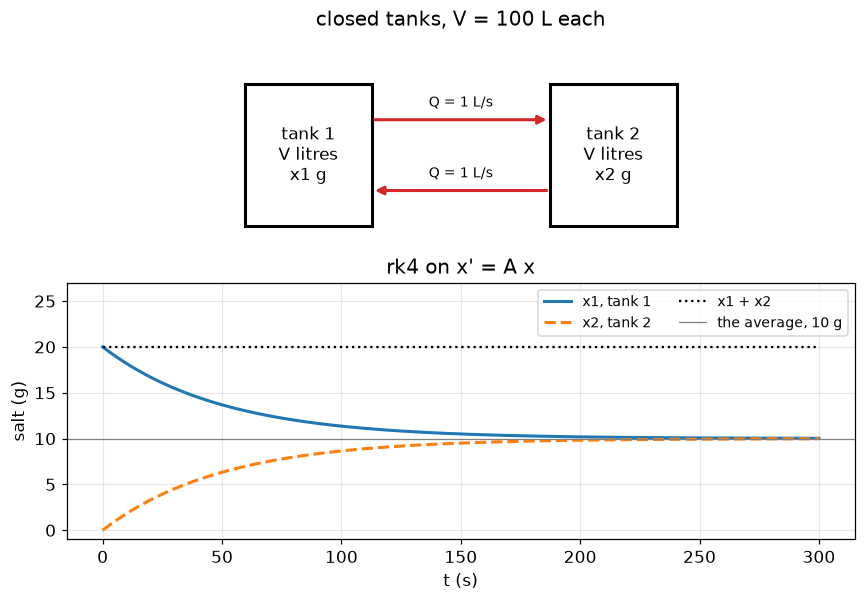

In [5]:
V_TANK = 100.0                  # L, each tank (a number chosen for this notebook)
Q_PUMP = 1.0                    # L/s, each pump
SALT_START = (20.0, 0.0)        # g, x1(0) and x2(0)
AVERAGE_SALT = sum(SALT_START) / 2      # g: what each tank holds in the end
T_TANKS = 300.0                 # s
TANK_STEP = 1.0                 # s

# drawing code: you can skip reading it
TANK_BOXES = {1: 0.0, 2: 2.4}   # left edge of each tank in the drawing (width and height 1)
PIPE_LENGTH = 1.4               # the pipes of clean water and of the drain, in the drawing
PIPE_LEVELS = {(1, 2): 0.75, (2, 1): 0.25, ("clean", 1): 0.85, (2, "drain"): 0.15}
LABEL_GAP = 0.07                # the label of a pipe, above its arrow
TANK_DRAWING_HEIGHT = (-0.1, 1.35)  # the vertical window of the drawing, labels included
TANKS_FIGURE = (8.0, 5.6)       # the drawing above, the salt below
TANK_WINDOW = (-1.0, 27.0)      # g: the salt axis of the plots of tanks


def draw_tanks(ax, pipes, title):
    # pipes: (source, target, label); source and target are 1, 2, "clean" (fresh water) or "drain"
    for number, left in TANK_BOXES.items():
        ax.add_patch(plt.Rectangle((left, 0.0), 1.0, 1.0, fill=False, linewidth=2))
        ax.text(left + 0.5, 0.5, f"tank {number}\nV litres\nx{number} g", ha="center", va="center")
    right_1, left_2, right_2 = TANK_BOXES[1] + 1.0, TANK_BOXES[2], TANK_BOXES[2] + 1.0
    ends = {(1, 2): (right_1, left_2), (2, 1): (left_2, right_1),
            ("clean", 1): (TANK_BOXES[1] - PIPE_LENGTH, TANK_BOXES[1]),
            (2, "drain"): (right_2, right_2 + PIPE_LENGTH)}
    for source, target, label in pipes:
        start, end = ends[(source, target)]
        level = PIPE_LEVELS[(source, target)]
        ax.annotate("", xy=(end, level), xytext=(start, level),
                    arrowprops={"arrowstyle": "-|>", "color": "C3", "lw": 2})
        ax.text((start + end) / 2, level + LABEL_GAP, label, ha="center", va="bottom", fontsize=9)
    ax.set_xlim(TANK_BOXES[1] - PIPE_LENGTH, right_2 + PIPE_LENGTH)
    ax.set_ylim(*TANK_DRAWING_HEIGHT)
    ax.set_axis_off()
    ax.set_title(title)


def tanks_figure(pipes, title):
    # a figure with the drawing of the tanks on top and an empty plot of the salt below it
    fig, (drawing, plot) = plt.subplots(2, 1, figsize=TANKS_FIGURE, gridspec_kw={"height_ratios": [0.8, 1]})
    draw_tanks(drawing, pipes, title)
    plot.set_xlabel("t (s)")
    plot.set_ylabel("salt (g)")
    return plot


closed_tanks = Q_PUMP / V_TANK * np.array([[-1.0, 1.0], [1.0, -1.0]])
times_tanks, salt = ol.rk4(lambda s, x: closed_tanks @ x, (0.0, T_TANKS), SALT_START, TANK_STEP)
# sum(axis=0): add down each column; sum(axis=1): add along each row (here x1 + x2 at each time)
print("A =\n", closed_tanks, "\neach column adds up to", closed_tanks.sum(axis=0))
print(f"after {T_TANKS:g} s: x1 = {salt[-1, 0]:.3f} g, x2 = {salt[-1, 1]:.3f} g; "
      f"the total stays between {salt.sum(axis=1).min():.6f} and {salt.sum(axis=1).max():.6f} g")
assert np.allclose(salt.sum(axis=1), sum(SALT_START))

plot = tanks_figure([(1, 2, f"Q = {Q_PUMP:g} L/s"), (2, 1, f"Q = {Q_PUMP:g} L/s")],
                    f"closed tanks, V = {V_TANK:g} L each")
plot.plot(times_tanks, salt[:, 0], "-", linewidth=2, label="x1, tank 1")
plot.plot(times_tanks, salt[:, 1], "--", linewidth=2, label="x2, tank 2")
plot.plot(times_tanks, salt.sum(axis=1), ":", color="black", label="x1 + x2")
plot.axhline(AVERAGE_SALT, color="gray", linewidth=0.8, label=f"the average, {AVERAGE_SALT:g} g")
plot.set_title("rk4 on x' = A x")
plot.set_ylim(*TANK_WINDOW)                                                # room for the legend
plot.legend(loc="upper right", ncol=2)
plt.tight_layout()
plt.show()

*The plot shows* the tanks and pumps; the salt in tank 1 (solid) falling from 20 g, in tank 2
(dashed) rising from 0, both towards the gray line at 10 g; the total (dotted) stays 20 g.

(Answer: 10 g in each tank; the total stays 20 g, because each **column** of $A$ adds up to 0, so
$x_1' + x_2' = 0$ by the line above the question.)

## 5. The eigenvalue method: real eigenvalues

$\vec{x} = \vec{v}\,e^{\lambda t}$ gives $\lambda\vec{v}e^{\lambda t} = A\vec{v}e^{\lambda t}$, so
$A\vec{v} = \lambda\vec{v}$. With $n$ distinct real eigenvalues the general solution is
$C_1\vec{v}_1e^{\lambda_1t} + \dots + C_n\vec{v}_ne^{\lambda_nt}$ (Lebl, Theorem 3.4.1; Lebl writes $P$ for
the system matrix there, and $c_1$ for $C_1$).

**The tanks by hand.** Trace $-2Q/V$, determinant 0: $\lambda^2 + (2Q/V)\lambda = 0$, so $\lambda = 0$ and
$\lambda = -0.02$ per second; the shortcut $(a_{12}, \lambda - a_{11})$ gives $(0.01, 0.01)$ and
$(0.01, -0.01)$, that is $(1, 1)$ and $(1, -1)$. Then ($e^{-t/50}$ is $e^{-0.02t}$; $X(0)C = (20, 0)$ is
$C_1 + C_2 = 20$, $C_1 - C_2 = 0$):

$$ X(t) = \begin{pmatrix} 1 & e^{-t/50} \\ 1 & -e^{-t/50} \end{pmatrix}, \qquad
   X(0)\,C = \begin{pmatrix} 20 \\ 0 \end{pmatrix} \Rightarrow C_1 = C_2 = 10, \qquad
   \vec{x} = 10\begin{pmatrix} 1 \\ 1 \end{pmatrix} + 10\begin{pmatrix} 1 \\ -1 \end{pmatrix}e^{-t/50} . $$

**Reading it.** The eigenvalue 0 is the part that never changes, the average; $-0.02$ per second is
the speed of mixing: the excess over the average shrinks like $e^{-0.02t}$, below 1 g after
$\ln(10)/0.02 = 115$ s.

*Lebl, Example 3.8.1* (the matrix of the figure of Section 2, $\vec{x}(0) = (4, 2)$): the columns of
$X(t)$ are $(1, 1)e^{3t}$ and $(1, -1)e^{-t}$; $C_1 + C_2 = 4$, $C_1 - C_2 = 2$ give $C = (3, 1)$, so
$\vec{x} = 3(1, 1)e^{3t} + (1, -1)e^{-t}$, the book's answer. The code checks that $X(t)X(0)^{-1}$ gives
the same.

the closed tanks: real distinct; trace -0.02, determinant 0; eigenvalues -0.02 and 0; eigenvectors [[0.01, -0.01], [0.01, 0.01]]
hand formula against eigen_solution : largest difference 0.0e+00 g
hand formula against expm           : largest difference 1.2e-13 g
hand formula against rk4, Section 4 : largest difference 5.0e-09 g
within 1 g of the average after ln(10) / 0.02 = 115.1 s
Example 3.8.1: e^(tA) = [[exp(3*t)/2 + exp(-t)/2, exp(3*t)/2 - exp(-t)/2], [exp(3*t)/2 - exp(-t)/2, exp(3*t)/2 + exp(-t)/2]] 
  x(t) = [3*exp(3*t) + exp(-t), 3*exp(3*t) - exp(-t)]


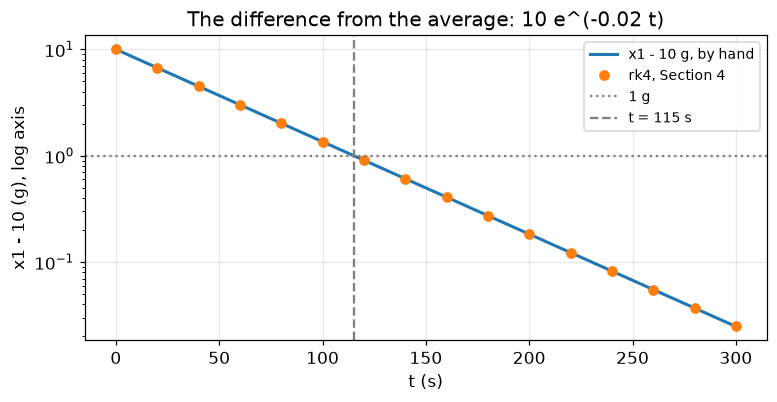

In [6]:
from scipy.linalg import expm                # expm(t * A) = e^(tA), the matrix exponential of Section 1

tanks_case = ol.two_by_two_case(closed_tanks)
report("the closed tanks", tanks_case)
EXCESS = SALT_START[0] - AVERAGE_SALT                       # g: the part of the eigenvalue -0.02 / s
decay = np.exp(tanks_case.eigenvalues[0] * times_tanks)
# np.column_stack puts two lists side by side as columns, like states of rk4
by_hand = np.column_stack([AVERAGE_SALT + EXCESS * decay,    # x1: 10 (1) + 10 e^(-0.02 t) (1)
                           AVERAGE_SALT - EXCESS * decay])   # x2: 10 (1) + 10 e^(-0.02 t) (-1)
by_library = ol.eigen_solution(times_tanks, closed_tanks, SALT_START)
by_expm = np.array([expm(closed_tanks * s) @ SALT_START for s in times_tanks])
for name, values in (("eigen_solution", by_library), ("expm", by_expm), ("rk4, Section 4", salt)):
    print(f"hand formula against {name:15s}: largest difference {np.max(np.abs(by_hand - values)):.1e} g")
assert np.allclose(by_hand, by_library) and np.allclose(by_hand, by_expm) and np.allclose(by_hand, salt)
GRAM = 1.0
LOG_MARKS = 20                              # a marker every 20 s on the log plot
within = np.log(EXCESS / GRAM) / -tanks_case.eigenvalues[0]
print(f"within {GRAM:g} g of the average after ln(10) / 0.02 = {within:.1f} s")

fundamental = sp.Matrix([[sp.exp(3 * t), sp.exp(-t)],
                         [sp.exp(3 * t), -sp.exp(-t)]])                  # Lebl, Example 3.8.1: X(t)
exponential = sp.expand(fundamental * fundamental.subs(t, 0).inv())       # .inv() is X(0)^(-1)
x_381 = sp.expand(exponential * sp.Matrix([4, 2]))
print("Example 3.8.1: e^(tA) =", exponential.tolist(), "\n  x(t) =", list(x_381))
book_381 = sp.Matrix([3 * sp.exp(3 * t) + sp.exp(-t), 3 * sp.exp(3 * t) - sp.exp(-t)])
assert sp.simplify(x_381 - book_381) == sp.zeros(2, 1)                               # the values of the book
assert np.allclose(np.array(exponential.subs(t, T_ONE), dtype=float), expm(T_ONE * matrix_381))

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.semilogy(times_tanks, by_hand[:, 0] - AVERAGE_SALT, "-", linewidth=2, label="x1 - 10 g, by hand")
ax.semilogy(times_tanks[::LOG_MARKS], (salt[:, 0] - AVERAGE_SALT)[::LOG_MARKS], "o", label="rk4, Section 4")
ax.axhline(GRAM, color="gray", linestyle=":", label="1 g")
ax.axvline(within, color="gray", linestyle="--", label=f"t = {within:.0f} s")
ax.set_xlabel("t (s)")
ax.set_ylabel("x1 - 10 (g), log axis")
ax.set_title("The difference from the average: 10 e^(-0.02 t)")
ax.legend(loc="upper right")
plt.show()

*The plot shows* the excess of salt in tank 1 over the average, on a logarithmic axis (each step up
is 10 times more, as in notebook 01): a straight line from 10 g, since it is $10e^{-0.02t}$ (its
steepness is set by the eigenvalue $-0.02$), crossing 1 g (dotted) at 115 s (dashed).

## 6. Complex and repeated eigenvalues

**Complex.** Lebl's $A = \begin{pmatrix} 1 & 1 \\ -1 & 1 \end{pmatrix}$: $\lambda^2 - 2\lambda + 2 = 0$,
$\lambda = 1 \pm i$. Lebl uses $\lambda = 1 - i$: the shortcut $(a_{12}, \lambda - a_{11})$ gives $(1, -i)$,
which is $-i$ times Lebl's $\vec{v} = (i, 1)$ (a complex multiple is still an eigenvector). Euler's formula
(video R05):

$$ \vec{v}\,e^{(1 - i)t} = \begin{pmatrix} i \\ 1 \end{pmatrix} e^{t}(\cos t - i\sin t)
   = e^{t}\begin{pmatrix} \sin t \\ \cos t \end{pmatrix}
   + i\,e^{t}\begin{pmatrix} \cos t \\ -\sin t \end{pmatrix} . $$

($i \cdot (-i\sin t) = \sin t$, since $i^2 = -1$.) The real and the imaginary part are each a real
solution (Lebl, Theorem 3.4.2); the other eigenvalue of the pair gives the same real part and minus
the imaginary part: nothing new.

**Repeated, one eigenvector.** *Lebl, Example 3.7.1*: $\begin{pmatrix} 3 & 1 \\ 0 & 3 \end{pmatrix}$ has
the eigenvalue 3 twice but only the eigenvectors $\vec{v} = (1, 0)$ and its multiples (one eigenvector
missing: Lebl calls this **defect** 1). As for a repeated root in notebook 06, multiply by $t$:
$(\vec{w} + \vec{v}\,t)e^{3t}$ is a solution exactly when $(A - 3I)\vec{w} = \vec{v}$, that is
$\begin{pmatrix} 0 & 1 \\ 0 & 0 \end{pmatrix}\vec{w} = \begin{pmatrix} 1 \\ 0 \end{pmatrix}$:
$\vec{w} = (0, 1)$, a **generalized eigenvector** (Lebl writes $\vec{v}_2$).

**A quick way to the pair ($2 \times 2$).** Take $\vec{w} = (1, 0)$ (or $(0, 1)$ if $(A - \lambda I)(1, 0)$ is
the zero vector, as for Example 3.7.1)
and put $\vec{v} = (A - \lambda I)\vec{w}$: it is an eigenvector, and $(A - \lambda I)\vec{w} = \vec{v}$ holds
by construction (it works because $(A - \lambda I)^2 = 0$ when $\lambda$ is repeated, Lebl 3.8). Every
eigenvector is $k\vec{v}$ for some number $k$, and then $(A - \lambda I)(k\vec{w}) = k\vec{v}$: a $\vec{w}$
exists for every eigenvector.

real part: [exp(t)*sin(t), exp(t)*cos(t)]   imaginary part: [exp(t)*cos(t), -exp(t)*sin(t)]
[[3, 1], [0, 3]]: repeated, one eigenvector; trace 6, determinant 9; eigenvalues 3 (twice); eigenvectors [[1.0, 0.0]]; generalized eigenvector w = [0.0, 1.0]


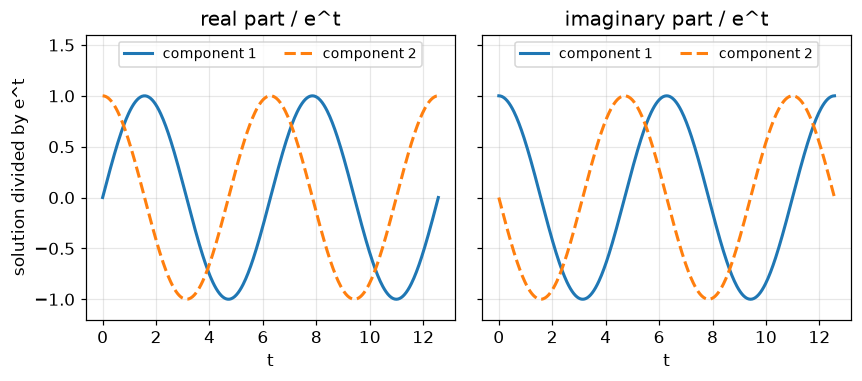

In [7]:
COMPLEX_EXAMPLE = sp.Matrix([[1, 1], [-1, 1]])                 # Lebl 3.4, complex eigenvalues
v_complex = sp.Matrix([sp.I, 1])
assert (COMPLEX_EXAMPLE - (1 - sp.I) * sp.eye(2)) * v_complex == sp.zeros(2, 1)
# applyfunc applies a function to every entry; expand_complex writes each as (real) + i (imaginary)
z = (v_complex * sp.exp((1 - sp.I) * t)).applyfunc(sp.expand_complex)
real_part, imaginary_part = z.applyfunc(sp.re), z.applyfunc(sp.im)   # the two parts of each entry
print("real part:", list(real_part), "  imaginary part:", list(imaginary_part))
for solution in (real_part, imaginary_part):
    assert sp.simplify(solution.diff(t) - COMPLEX_EXAMPLE * solution) == sp.zeros(2, 1)
book_real = sp.exp(t) * sp.Matrix([sp.sin(t), sp.cos(t)])
assert sp.simplify(real_part - book_real) == sp.zeros(2, 1)                           # the values of the book

DEFECTIVE = np.array([[3.0, 1.0], [0.0, 3.0]])                # Lebl, Example 3.7.1
case_371 = ol.two_by_two_case(DEFECTIVE)
report("[[3, 1], [0, 3]]", case_371)
assert np.array_equal(case_371.eigenvectors[0], [1, 0])                               # the values of the book
assert np.array_equal(case_371.generalized, [0, 1])                                   # the values of the book
v_371, w_371 = sp.Matrix([1, 0]), sp.Matrix([0, 1])
second = (w_371 + v_371 * t) * sp.exp(3 * t)
assert sp.simplify(second.diff(t) - sp.Matrix(DEFECTIVE.astype(int)) * second) == sp.zeros(2, 1)

# Lebl's simple case (Section 3.8), the model for Exercise 4(ii): A = 3I + B with B^2 = 0, so
# e^(tA) = e^(3t) e^(tB) = e^(3t) (I + t B): the series of e^(tB) stops, as B^2 = 0
SIMPLE = np.array([[5.0, 4.0], [-1.0, 1.0]])
B = SIMPLE - 3 * np.eye(2)
assert np.array_equal(B @ B, np.zeros((2, 2)))


def simple_exponential(s):
    return np.exp(3 * s) * np.array([[1 + 2 * s, 4 * s], [-s, 1 - 2 * s]])     # the formula of the book


SIMPLE_CHECK_TIMES = np.linspace(0.0, 1.0, 11)
assert all(np.allclose(simple_exponential(s), expm(s * SIMPLE)) for s in SIMPLE_CHECK_TIMES)

# the two real solutions divided by e^t, so that the turning is visible (it would be hidden by e^t)
T_COMPLEX = 4 * np.pi
COMPLEX_WINDOW = (-1.2, 1.6)                # room for the legends above the curves
times_complex = np.linspace(0.0, T_COMPLEX, N_POINTS)
fig, panels = plt.subplots(1, 2, figsize=FIGURE_SIZE, sharey=True)
for panel, solution, name in zip(panels, (real_part, imaginary_part), ("real part", "imaginary part")):
    for index, style in ((0, "-"), (1, "--")):
        divided = sp.lambdify(t, solution[index] * sp.exp(-t), "numpy")
        values = divided(times_complex) * np.ones_like(times_complex)
        panel.plot(times_complex, values, style, linewidth=2, label=f"component {index + 1}")
    panel.set_xlabel("t")
    panel.set_title(f"{name} / e^t")
    panel.set_ylim(*COMPLEX_WINDOW)
    panel.legend(loc="upper center", ncol=2)
panels[0].set_ylabel("solution divided by e^t")
plt.tight_layout()
plt.show()

*The plot shows* the two real solutions divided by $e^{t}$ (left: real part, right: imaginary part;
solid: first component, dashed: second): sines and cosines of period $2\pi$, from the imaginary part
1 of the eigenvalue; each turns round and round. The factor $e^{t}$, from the real part 1, makes the
true solutions grow, to $e^{2\pi} \approx 535$ at $t = 2\pi$.

**Slider: three cases in one family.** The state $(x, x')$ of $x'' + c\,x' + x = 0$ (notebook 07 with
$m = k = 1$, so $x$ and $t$ have no units; $x > 0$ in the positive direction of notebook 07; $c$ is the
damping) solves $\vec{u}\,' = A\vec{u}$,
$A = \begin{pmatrix} 0 & 1 \\ -1 & -c \end{pmatrix}$. Its eigenvalues are the roots of $r^2 + cr + 1 = 0$
(Section 3), as in notebook 07. Before moving it: at $c = 2$ the eigenvalues are equal. Does the
motion change suddenly when $c$ passes 2?

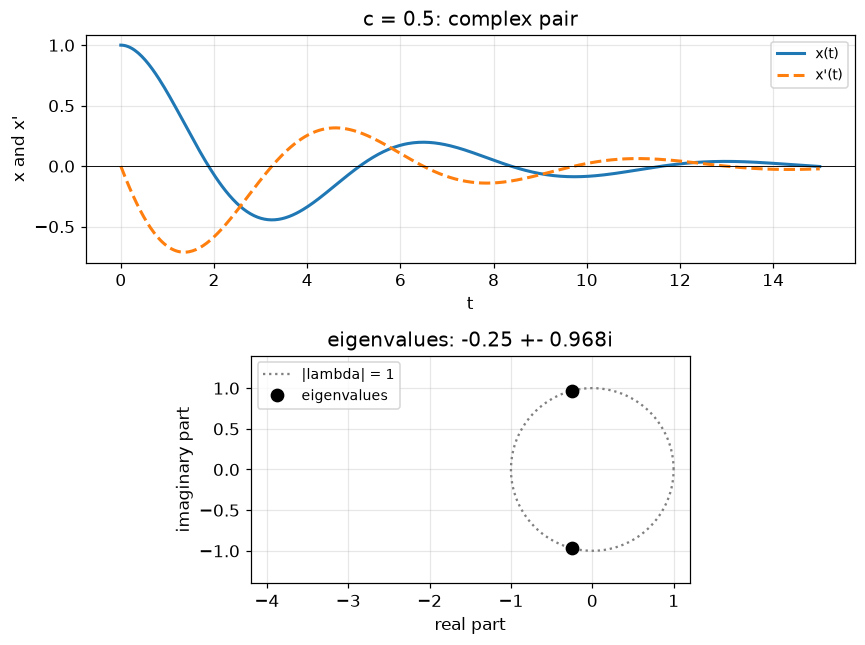

In [8]:
DEFAULT_C = 0.5
C_RANGE = (0.0, 4.0, 0.1)                   # minimum, maximum, step
T_CASES = 15.0
CIRCLE = np.linspace(0.0, 2 * np.pi, 200)   # |lambda| = 1, where complex eigenvalues travel
PLANE = (-4.2, 1.2, -1.4, 1.4)              # the window of the eigenvalue plane
CASES_FIGURE = (8.0, 6.0)                   # the motion above, the eigenvalues below


def plot_cases(c=DEFAULT_C):
    # x'' + c x' + x = 0 from x(0) = 1, x'(0) = 0, by the formula of its case
    matrix = np.array([[0.0, 1.0], [-1.0, -c]])
    case = ol.two_by_two_case(matrix)
    times = np.linspace(0.0, T_CASES, N_POINTS)
    state = ol.eigen_solution(times, matrix, [1.0, 0.0])
    fig, panels = plt.subplots(2, 1, figsize=CASES_FIGURE, gridspec_kw={"height_ratios": [1, 1]})
    panels[0].plot(times, state[:, 0], "-", linewidth=2, label="x(t)")
    panels[0].plot(times, state[:, 1], "--", linewidth=2, label="x'(t)")
    panels[0].axhline(0.0, color="black", linewidth=0.6)
    panels[0].set_xlabel("t")
    panels[0].set_ylabel("x and x'")
    panels[0].legend(loc="upper right")
    panels[0].set_title(f"c = {c:.1f}: {case.case}")
    eigenvalues = np.array(case.eigenvalues, dtype=complex)
    panels[1].plot(np.cos(CIRCLE), np.sin(CIRCLE), ":", color="gray", label="|lambda| = 1")
    panels[1].plot(eigenvalues.real, eigenvalues.imag, "o", color="black", markersize=8, label="eigenvalues")
    panels[1].axis(PLANE)
    panels[1].set_aspect("equal")
    panels[1].set_xlabel("real part")
    panels[1].set_ylabel("imaginary part")
    panels[1].set_title(f"eigenvalues: {describe(case)}")
    panels[1].legend(loc="upper left")
    plt.tight_layout()
    plt.show()


plot_cases()

In [9]:
interact(plot_cases, c=FloatSlider(value=DEFAULT_C, min=C_RANGE[0], max=C_RANGE[1], step=C_RANGE[2],
                                   description="c", continuous_update=False));

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='c', max=4.0), Output()), _d...

*The static plot shows*, for $c = 0.5$, $x$ (solid) and $x'$ (dashed) oscillating and dying out; the
pair $-0.25 \pm 0.968i$ lies on the dotted circle. (The two eigenvalues multiply to $\det A = 1$; a
complex pair $\alpha \pm i\beta$ multiplies to $\alpha^2 + \beta^2$, so it lies on the circle of radius 1.)

(Answer: no jump. Towards $c = 2$ the pair slides along the circle to $-1$, twice; there
$x = (1 + t)e^{-t}$, the "times $t$" bridge of notebook 06's merging roots. At $c = 0$ the
eigenvalues are $\pm i$: nothing decays.)

## 7. Two masses on springs

**Conventions (carts).** $x_1$, $x_2$: displacements from the rest positions (springs neither
stretched nor compressed) in metres, **positive away from the wall** (to the right in the figure);
$x'$, the velocity, positive to the right; masses in kg, springs in N/m, $t$ in s (Lebl's Example
3.6.1 has no units: these are the notebook's). A spring stretched by $d$ pulls both ends inwards
with the force $k\,d$.

*Lebl, Example 3.6.1*: wall, spring $k_1 = 4$, cart 1 ($m_1 = 2$), spring $k_2 = 2$, cart 2 ($m_2 = 1$).
Spring 1 is stretched by $x_1$, spring 2 by $x_2 - x_1$. Newton's law:
* cart 1: spring 1 pulls it towards the wall, $-k_1x_1$; spring 2 towards cart 2, $+k_2(x_2 - x_1)$:
  $m_1x_1'' = -k_1x_1 + k_2(x_2 - x_1)$;
* cart 2: spring 2 pulls it towards cart 1: $m_2x_2'' = -k_2(x_2 - x_1)$.

With the mass matrix $M$ and the stiffness matrix $K$, $M\vec{x}\,'' = K\vec{x}$ (Lebl puts the minus
signs inside $K$; many books write $M\vec{x}\,'' + K\vec{x} = \vec{0}$):

$$ \begin{pmatrix} 2 & 0 \\ 0 & 1 \end{pmatrix}\vec{x}\,''
   = \begin{pmatrix} -6 & 2 \\ 2 & -2 \end{pmatrix}\vec{x},
   \qquad A = M^{-1}K = \begin{pmatrix} -3 & 1 \\ 2 & -2 \end{pmatrix} . $$

Try $\vec{x} = \vec{v}\cos\omega t$: then $\vec{x}\,'' = -\omega^2\vec{v}\cos\omega t$, so it is a solution
when $A\vec{v} = -\omega^2\vec{v}$ (and so is $\vec{v}\sin\omega t$). The eigenvalues $-1$, $-4$ give the
**natural frequencies** $\omega_1 = 1$ rad/s, $\omega_2 = 2$ rad/s (Lebl, Theorem 3.6.1; not notebook 07's
pseudo-frequency), with the **modes** $\vec{v}_1 = (1, 2)$ (together) and $\vec{v}_2 = (1, -1)$ (opposite):
$\vec{x} = \vec{v}_1(C_1\cos t + C_2\sin t) + \vec{v}_2(C_3\cos 2t + C_4\sin 2t)$ (Lebl: $a_i$, $b_i$).

**By hand**, for $\vec{x}(0) = (1, -1)$ m, $\vec{x}\,'(0) = (0, 6)$ m/s:
$C_1\vec{v}_1 + C_3\vec{v}_2 = (1, -1)$ gives $C_1 = 0$, $C_3 = 1$; $C_2\vec{v}_1 + 2C_4\vec{v}_2 = (0, 6)$
(the velocity: the derivative of $C_2\sin t$ at 0 is $C_2$, of $C_4\sin 2t$ is $2C_4$) gives $C_2 = 2$,
$C_4 = -1$:

$$ x_1 = 2\sin t + \cos 2t - \sin 2t, \qquad x_2 = 4\sin t - \cos 2t + \sin 2t . $$

The code also solves the carts as four equations of order 1 (Section 3), with `expm`: the same curves.

eigenvalues (-4.0, -1.0) -> natural frequencies (rad/s) [1. 2.] 
modes (columns):
 [[ 1.  1.]
 [ 2. -1.]]
C1, C3 = [0. 1.]   C2, C4 = [ 2. -1.]   (the amounts of the slow and the fast mode)
eigenvalues of the 4 x 4 matrix: i times [-2. -1.  1.  2.]
at t = 3 s: by hand [ 1.52183 -0.67511], expm of the 4 x 4 matrix [ 1.52183 -0.67511]


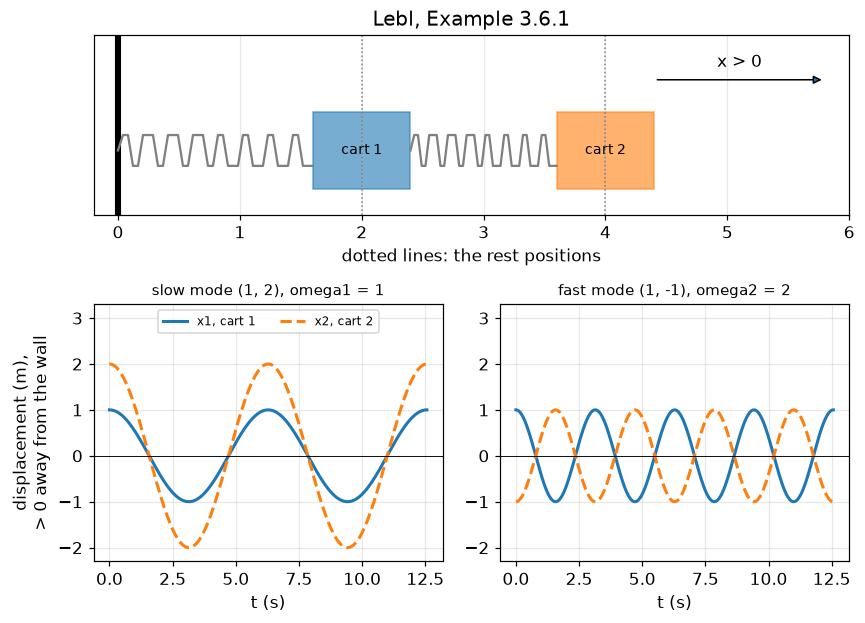

In [10]:
MASSES = (2.0, 1.0)                         # kg: cart 1 (next to the wall), cart 2
SPRINGS = (4.0, 2.0)                        # N/m: k1 (wall - cart 1), k2 (cart 1 - cart 2)
POSITION_START = np.array([1.0, -1.0])      # m
VELOCITY_START = np.array([0.0, 6.0])       # m/s
T_CHECK = 3.0                               # s
T_CARTS = 4 * np.pi
MODE_WINDOW = (-2.3, 3.3)                   # m: the axes of the modes
BOTH_WINDOW = (-5.0, 9.0)                   # m: the axes of the solution
k1, k2 = SPRINGS
M = np.diag(MASSES)
K = np.array([[-(k1 + k2), k2], [k2, -k2]])
A_carts = np.linalg.solve(M, K)                                           # M^(-1) K
assert np.array_equal(A_carts, [[-3, 1], [2, -2]])                         # the values of the book
case_carts = ol.two_by_two_case(A_carts)
# omega = sqrt(-eigenvalue); [::-1] reverses the order, so omega1 < omega2
frequencies = np.sqrt(-np.array(case_carts.eigenvalues))[::-1]
modes = np.column_stack(case_carts.eigenvectors[::-1])                    # columns: the slow, the fast mode
modes = modes / modes[0]       # divide each column by its first entry: the modes (1, 2) and (1, -1)
print("eigenvalues", case_carts.eigenvalues, "-> natural frequencies (rad/s)", frequencies,
      "\nmodes (columns):\n", modes)
amounts_a = np.linalg.solve(modes, POSITION_START)
amounts_b = np.linalg.solve(modes * frequencies, VELOCITY_START)  # each column times its omega: x'(0)
print("C1, C3 =", amounts_a, "  C2, C4 =", amounts_b, "  (the amounts of the slow and the fast mode)")
assert np.allclose(amounts_a, [0, 1]) and np.allclose(amounts_b, [2, -1])  # the values of the book


def by_modes(s, a, b):
    # the carts' positions (one row for each time) from the amounts a and b of the two modes
    s = np.asarray(s, dtype=float)[..., np.newaxis]     # makes s a column: each time gets its own row
    return (a[0] * np.cos(frequencies[0] * s) + b[0] * np.sin(frequencies[0] * s)) * modes[:, 0] \
        + (a[1] * np.cos(frequencies[1] * s) + b[1] * np.sin(frequencies[1] * s)) * modes[:, 1]


# As four equations of order 1 (Section 3): u = (x1, x2, x1', x2'); the first two rows say u1' = u3,
# u2' = u4, the last two are x'' = A x. The 4 x 4 matrix [[0, I], [A, 0]] is built from four 2 x 2
# blocks; its eigenvalues are +-i and +-2i (i omega for each natural frequency).
first_order = np.block([[np.zeros((2, 2)), np.eye(2)], [A_carts, np.zeros((2, 2))]])
eigenvalues_4 = np.linalg.eigvals(first_order)
assert np.allclose(eigenvalues_4.real, 0.0)
print("eigenvalues of the 4 x 4 matrix: i times",
      np.sort(eigenvalues_4.imag).round(12) + 0.0)                      # + 0.0 turns -0.0 into 0.0
start_4 = np.concatenate([POSITION_START, VELOCITY_START])
at_check = (expm(T_CHECK * first_order) @ start_4)[:2]
print(f"at t = {T_CHECK:g} s: by hand {np.round(by_modes(T_CHECK, amounts_a, amounts_b), 5)}, "
      f"expm of the 4 x 4 matrix {np.round(at_check, 5)}")
assert np.allclose(by_modes(T_CHECK, amounts_a, amounts_b), at_check)

# drawing code: you can skip reading it
CART_PLACES = (2.0, 4.0)                    # where the carts are drawn at rest
CART_HALF_WIDTH, CART_BOTTOM, CART_HEIGHT = 0.4, 0.2, 0.6
SPRING_LEVEL, COIL_SIZE, COIL_TURNS, COIL_POINTS = 0.5, 0.12, 8, 40
ARROW = ((4.4, 1.05), (5.8, 1.05))          # the arrow "x > 0"
DRAWING_WINDOW = (-0.2, 6.0, 0.0, 1.4)
CARTS_FIGURE = (8.0, 5.8)                   # the drawing above, the two modes below


def draw_carts(ax):
    # the wall, two springs and the two carts at rest, and the positive direction
    ax.axvline(0.0, color="black", linewidth=4)
    left = 0.0
    for number, centre in enumerate(CART_PLACES, start=1):
        coils = np.linspace(left, centre - CART_HALF_WIDTH, COIL_POINTS)
        zigzag = np.sign(np.sin(np.linspace(0.0, 2 * np.pi * COIL_TURNS, coils.size)))
        ax.plot(coils, SPRING_LEVEL + COIL_SIZE * zigzag, color="gray")
        ax.add_patch(plt.Rectangle((centre - CART_HALF_WIDTH, CART_BOTTOM), 2 * CART_HALF_WIDTH, CART_HEIGHT,
                                   color=f"C{number - 1}", alpha=0.6))
        ax.text(centre, SPRING_LEVEL, f"cart {number}", ha="center", va="center", fontsize=9)
        ax.axvline(centre, color="gray", linestyle=":", linewidth=1)
        left = centre + CART_HALF_WIDTH
    ax.annotate("", xy=ARROW[1], xytext=ARROW[0], arrowprops={"arrowstyle": "-|>"})
    ax.text((ARROW[0][0] + ARROW[1][0]) / 2, ARROW[0][1] + LABEL_GAP, "x > 0", ha="center", va="bottom")
    ax.axis(DRAWING_WINDOW)
    ax.set_yticks([])
    ax.set_xlabel("dotted lines: the rest positions")


times_carts = np.linspace(0.0, T_CARTS, N_POINTS)
fig = plt.figure(figsize=CARTS_FIGURE)
grid = fig.add_gridspec(2, 2, height_ratios=[0.7, 1])
drawing = fig.add_subplot(grid[0, :])
draw_carts(drawing)
drawing.set_title("Lebl, Example 3.6.1")
panels = [fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])]
MODE_NAMES = ("slow mode (1, 2), omega1 = 1", "fast mode (1, -1), omega2 = 2")
for panel, column, name in zip(panels, (0, 1), MODE_NAMES):
    shape = np.cos(frequencies[column] * times_carts)[:, None] * modes[:, column]
    panel.plot(times_carts, shape[:, 0], "-", linewidth=2, label="x1, cart 1")
    panel.plot(times_carts, shape[:, 1], "--", linewidth=2, label="x2, cart 2")
    panel.axhline(0.0, color="black", linewidth=0.6)
    panel.set_xlabel("t (s)")
    panel.set_ylim(*MODE_WINDOW)                                   # room for the legend
    panel.set_title(name, fontsize=10)
panels[0].set_ylabel("displacement (m),\n> 0 away from the wall")
panels[0].legend(loc="upper center", ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

*The plot shows* the carts at rest (dotted) and the modes (Lebl's Figure 3.6.3): slow, cart 2
(dashed) swings twice as far as cart 1 (solid), same side, period $2\pi$; fast, mirror images,
period $\pi$.

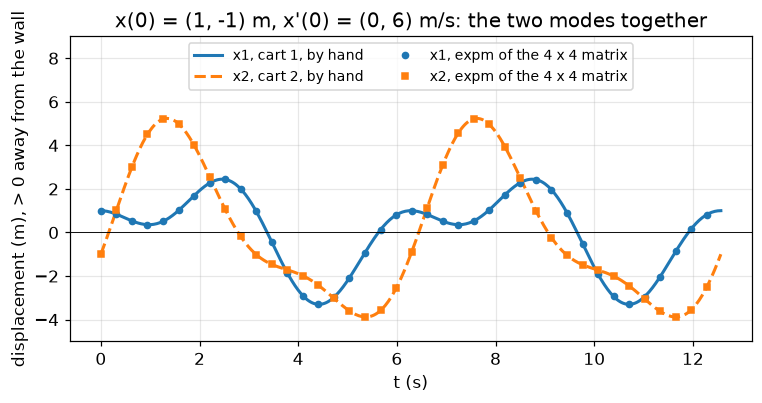

In [11]:
by_hand = by_modes(times_carts, amounts_a, amounts_b)
by_expm = np.array([(expm(s * first_order) @ start_4)[:2] for s in times_carts[::MARK_EVERY]])
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(times_carts, by_hand[:, 0], "-", linewidth=2, label="x1, cart 1, by hand")
ax.plot(times_carts, by_hand[:, 1], "--", linewidth=2, label="x2, cart 2, by hand")
ax.plot(times_carts[::MARK_EVERY], by_expm[:, 0], "o", markersize=4, color="C0",
        label="x1, expm of the 4 x 4 matrix")
ax.plot(times_carts[::MARK_EVERY], by_expm[:, 1], "s", markersize=4, color="C1",
        label="x2, expm of the 4 x 4 matrix")
ax.axhline(0.0, color="black", linewidth=0.6)
ax.set_xlabel("t (s)")
ax.set_ylabel("displacement (m), > 0 away from the wall")
ax.set_title("x(0) = (1, -1) m, x'(0) = (0, 6) m/s: the two modes together")
ax.set_ylim(*BOTH_WINDOW)                                                  # room for the legend
ax.legend(loc="upper center", ncol=2)
plt.show()

*The plot shows* Lebl's Figure 3.6.4: both modes mixed, no single period; the `expm` markers lie on
the curves found by hand.

**Slider: the two modes.** Cart 1 starts at $x_1(0) = 1$ m, cart 2 where the slider says, both at rest.
Before moving it: is there a start from which both carts swing with one frequency only?

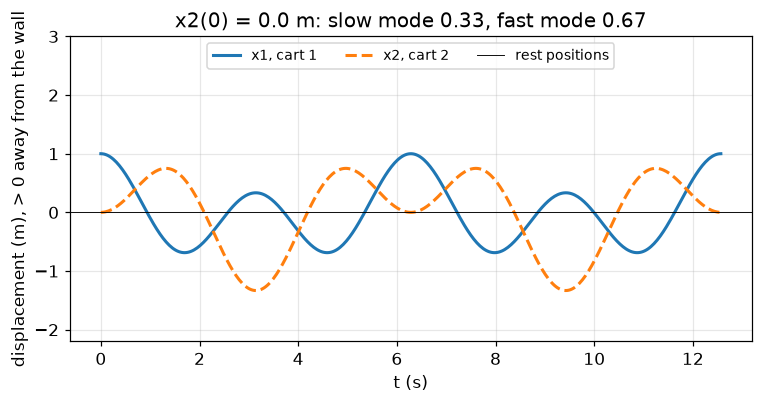

In [12]:
DEFAULT_X2 = 0.0
X2_RANGE = (-2.0, 2.0, 0.1)                 # m: minimum, maximum, step
CART_1_START = 1.0                          # m
NO_VELOCITY = np.zeros(2)
SLIDER_WINDOW = (-2.2, 3.0)                 # m: the largest displacement is 2 m; room for the legend


def plot_modes(x2_start=DEFAULT_X2):
    # the carts released from rest at x1(0) = 1 m and x2(0) = x2_start
    amounts = np.linalg.solve(modes, [CART_1_START, x2_start])         # (1 + x2(0)) / 3 and (2 - x2(0)) / 3
    positions = by_modes(times_carts, amounts, NO_VELOCITY)
    slow, fast = (round(value, 2) + 0.0 for value in amounts)
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ax.plot(times_carts, positions[:, 0], "-", linewidth=2, label="x1, cart 1")
    ax.plot(times_carts, positions[:, 1], "--", linewidth=2, label="x2, cart 2")
    ax.axhline(0.0, color="black", linewidth=0.6, label="rest positions")
    ax.set_ylim(*SLIDER_WINDOW)
    ax.set_xlabel("t (s)")
    ax.set_ylabel("displacement (m), > 0 away from the wall")
    ax.set_title(f"x2(0) = {x2_start:.1f} m: slow mode {slow:.2f}, fast mode {fast:.2f}")
    ax.legend(loc="upper center", ncol=3)
    plt.show()


plot_modes()

In [13]:
interact(plot_modes,
         x2_start=FloatSlider(value=DEFAULT_X2, min=X2_RANGE[0], max=X2_RANGE[1], step=X2_RANGE[2],
                              description="x2(0) (m)", continuous_update=False));

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='x2(0) (m)', max=2.0, min=-2...

*The static plot shows* $x_2(0) = 0$: $1/3$ slow mode, $2/3$ fast mode; cart 1 (solid) between
$-0.69$ and 1 m, cart 2 (dashed) between $-1.33$ and 0.75 m.

(Answer: yes, two: the starts shaped like a mode. Exercise 4(i) asks you to find them.)

## 8. Exercises

Final answers are at the end; try first. After Session 17: Exercise 1 (a)-(c) and Exercise 3; after
Session 18: the rest.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

* (a) *(Lebl, Exercise 3.4.1)* A $3 \times 3$ matrix $A$ has the eigenvalue 3 with the eigenvector
  $\vec{v} = (1, -1, 3)$. What is $A\vec{v}$? (A list of three numbers.)
* (b) *(From Lebl, Exercise 3.1.4)* How many equations of order 1 replace the system
  $x'' + y^2y' - x^3 = \sin t$, $y'' + (x' + y')^2 - x = 0$? (Here the unknowns are $x(t)$, $y(t)$, the
  independent variable $t$. Section 3: each equation of order $n$ gives $n$ unknowns, linear or not.)
* (c) *(From Lebl, Exercise 3.4.7)* The eigenvalues of
  $\begin{pmatrix} 2 & 7 & -1 \\ 0 & -3 & 5 \\ 0 & 0 & 4 \end{pmatrix}$, in increasing order.
* (d) *(Lebl, Exercise 3.6.4)* Carts as in Section 7 (positive away from the wall), with
  $m_1 = m_2 = 1$ kg and $k_1 = k_2 = 1$ N/m. True or False: cart 1 can move while cart 2 stays at
  rest all the time? (Write Newton's law for cart 2 as in Section 7 and put $x_2 = 0$ for all $t$.)

In [14]:
my_Av = None
my_equations = None
my_triangular = None
my_one_cart_moves = None        # True or False
# ---- your answers go above this line; the lines below check them (nothing to change) ----


def check_in_order(label, answer, expected):
    # ol.check_vector, with a hint when the right values come in another order
    try:
        mixed = (answer is not None and not np.allclose(answer, expected)
                 and np.allclose(np.sort(np.asarray(answer, dtype=float)), np.sort(expected)))
    except (TypeError, ValueError):
        mixed = False
    if mixed:
        print(f"{label}: not yet (right values: write them in increasing order)")
        return False
    return ol.check_vector(label, answer, expected)


EIGENVECTOR_341, EIGENVALUE_341 = np.array([1, -1, 3]), 3            # Lebl, Exercise 3.4.1
EQUATIONS_314, ORDER_314 = 2, 2                                      # Lebl, Exercise 3.1.4
TRIANGULAR = np.array([[2, 7, -1], [0, -3, 5], [0, 0, 4]])
UNIT_MASSES, UNIT_SPRINGS = (1.0, 1.0), (1.0, 1.0)                   # Lebl, Exercise 3.6.4
unit_carts = np.array([[-(UNIT_SPRINGS[0] + UNIT_SPRINGS[1]), UNIT_SPRINGS[1]],
                       [UNIT_SPRINGS[1], -UNIT_SPRINGS[1]]]) / np.array(UNIT_MASSES)[:, None]
ol.check_vector("Exercise 1a", my_Av, EIGENVALUE_341 * EIGENVECTOR_341)
ol.check("Exercise 1b", my_equations, EQUATIONS_314 * ORDER_314)
check_in_order("Exercise 1c", my_triangular, np.sort(np.linalg.eigvals(TRIANGULAR).real))
ol.check("Exercise 1d", my_one_cart_moves, bool(unit_carts[1, 0] == 0));

Exercise 1a: no answer yet (replace None with your value)
Exercise 1b: no answer yet (replace None with your value)
Exercise 1c: no answer yet (replace None with your value)
Exercise 1d: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

**(a)** *Lebl, Exercise 3.4.3.* $x_1' = 3x_1 + x_2$, $x_2' = 2x_1 + 4x_2$: the eigenvalues in increasing
order, and one eigenvector for each (any nonzero multiple is accepted).

**(b)** *From Lebl, Exercise 3.4.4.* $x_1' = x_1 - 2x_2$, $x_2' = 2x_1 + x_2$: the eigenvalue with positive
imaginary part (type $i$ as `1j`: $3 + 4i$ is `3 + 4j`), an eigenvector for it (any complex multiple is
accepted), and the real solution with $\vec{x}(0) = (1, 0)$, as two SymPy formulas in `t`. First step:
write the real and the imaginary part of $\vec{v}e^{\lambda t}$ as in Section 6; then find $C_1$, $C_2$ with
$C_1(\text{real part}) + C_2(\text{imaginary part}) = (1, 0)$ at $t = 0$, as $X(0)C = \vec{x}(0)$ in
Section 5.

**(c)** *From Lebl, Exercise 3.7.1* (the theory exercise of Session 18).
$A = \begin{pmatrix} 5 & -3 \\ 3 & -1 \end{pmatrix}$: the repeated eigenvalue, an eigenvector $\vec{v}$,
and a generalized eigenvector $\vec{w}$ with $(A - \lambda I)\vec{w} = \vec{v}$ for **your** $\vec{v}$.
(Section 6: the quick way gives a pair in two lines.)

**(d)** *Lebl, Exercise 3.6.7* (the practical exercise of Session 18). Convention: as in Section 7,
positive away from the wall, in m; the book's letters: $x_1$ for the 2 kg cart (the book's "first
cart", the one away from the wall), $x_2$ for the 3 kg cart. A 2 kg cart is joined by a spring of
1 N/m to a 3 kg cart, which is joined to the wall by a spring of 1 N/m. The 2 kg cart starts 1 m
from its rest position, away from the wall; the 3 kg cart at its rest position; both are let go from
rest. Type $x_2(t)$ as a SymPy formula in `t`. First step: as in Section 7, say by how much each
spring is stretched (the spring at the wall by $x_2$, the other by $x_1 - x_2$) and write Newton's law for
each cart; then $A = M^{-1}K$, its eigenvalues, the modes, and the amounts of the modes from
$\vec{x}(0) = (1, 0)$ m (from rest: cosines only, as in slider 2).

In [15]:
my_eigenvalues = None           # (a) a list of two numbers
my_v_for_low = None             # (a) for the smaller eigenvalue, a list of two numbers
my_v_for_high = None            # (a) for the larger eigenvalue
my_complex_eigenvalue = None    # (b)
my_complex_vector = None        # (b)
my_x1 = None                    # (b) a formula in t
my_x2 = None                    # (b) a formula in t
my_repeated = None              # (c)
my_v = None                     # (c)
my_w = None                     # (c)
my_cart_3kg = None              # (d) a formula in t
# ---- your answers go above this line; the lines below check them (nothing to change) ----

CHECK_WINDOW_344 = (0.0, 2.0)       # s: where the formulas of (b) are compared
CHECK_WINDOW_367 = (0.0, 10.0)      # s: where the formula of (d) is compared
EXERCISE_343 = [[3, 1], [2, 4]]
case_343 = ol.two_by_two_case(EXERCISE_343)
check_in_order("Exercise 2a, eigenvalues", my_eigenvalues, case_343.eigenvalues)
ol.check_vector("Exercise 2a, eigenvector for the smaller", my_v_for_low, case_343.eigenvectors[0],
                up_to_scale=True)
ol.check_vector("Exercise 2a, eigenvector for the larger", my_v_for_high, case_343.eigenvectors[1],
                up_to_scale=True)

EXERCISE_344 = [[1, -2], [2, 1]]
START_344 = [1, 0]
case_344 = ol.two_by_two_case(EXERCISE_344)
ol.check("Exercise 2b, eigenvalue", my_complex_eigenvalue, case_344.eigenvalues[0])
ol.check_vector("Exercise 2b, eigenvector", my_complex_vector, case_344.eigenvectors[0], up_to_scale=True)
vector_344 = sp.Matrix([sp.nsimplify(complex(entry)) for entry in case_344.eigenvectors[0]])
z_344 = (vector_344 * sp.exp(sp.nsimplify(case_344.eigenvalues[0]) * t)).applyfunc(sp.expand_complex)
parts = sp.Matrix.hstack(z_344.applyfunc(sp.re), z_344.applyfunc(sp.im))
expected_344 = parts * parts.subs(t, 0).solve(sp.Matrix(START_344))
assert np.allclose(np.array(expected_344.subs(t, T_ONE), dtype=float).ravel(),
                   ol.eigen_solution(T_ONE, EXERCISE_344, START_344))
ol.check_formula("Exercise 2b, x1", my_x1, expected_344[0], t, CHECK_WINDOW_344)
ol.check_formula("Exercise 2b, x2", my_x2, expected_344[1], t, CHECK_WINDOW_344)

EXERCISE_371 = np.array([[5.0, -3.0], [3.0, -1.0]])
case_ex371 = ol.two_by_two_case(EXERCISE_371)
ol.check("Exercise 2c, eigenvalue", my_repeated, case_ex371.eigenvalues[0])
v_is_right = ol.check_vector("Exercise 2c, v", my_v, case_ex371.eigenvectors[0], up_to_scale=True)
if my_w is None:
    print("Exercise 2c, w: no answer yet (replace None with your vector)")
elif not v_is_right:
    print("Exercise 2c, w: not yet (find an eigenvector v first: w is found from your v)")
else:
    try:
        shifted = EXERCISE_371 - case_ex371.eigenvalues[0] * np.eye(2)
        image = shifted @ np.asarray(my_w, dtype=complex).ravel()        # a SymPy column becomes a list
        target = np.asarray(my_v, dtype=complex).ravel()
        same = np.linalg.norm(image - target) <= ol.CHECK_TOLERANCE * np.linalg.norm(target)
        shown = np.round(image, 6).tolist() if np.any(image.imag) else np.round(image.real, 6).tolist()
        message = f"not yet ((A - lambda I) w must be your v; with your w it is {shown})"
        w_message = "correct" if same else message
    except (TypeError, ValueError):
        w_message = "not yet (a list of two numbers is expected)"
    print("Exercise 2c, w:", w_message)

MASS_FAR, MASS_WALL, SPRING_367 = sp.Integer(2), sp.Integer(3), sp.Integer(1)    # kg, kg, N/m
carts_367 = sp.Matrix([[-SPRING_367 / MASS_FAR, SPRING_367 / MASS_FAR],         # x1: the 2 kg cart
                       [SPRING_367 / MASS_WALL, -2 * SPRING_367 / MASS_WALL]])   # x2: the 3 kg cart
eigen_367 = carts_367.eigenvects()
modes_367 = sp.Matrix.hstack(*[vectors[0] for value, times_, vectors in eigen_367])
amounts_367 = modes_367.solve(sp.Matrix([1, 0]))                                # x(0) = (1, 0) m
expected_367 = sum((amount * vectors[0] * sp.cos(sp.sqrt(-value) * t)          # from rest: cosines only
                    for amount, (value, times_, vectors) in zip(amounts_367, eigen_367)), sp.zeros(2, 1))
ol.check_formula("Exercise 2d", my_cart_3kg, expected_367[1], t, CHECK_WINDOW_367);

Exercise 2a, eigenvalues: no answer yet (replace None with your value)
Exercise 2a, eigenvector for the smaller: no answer yet (replace None with your value)
Exercise 2a, eigenvector for the larger: no answer yet (replace None with your value)
Exercise 2b, eigenvalue: no answer yet (replace None with your value)
Exercise 2b, eigenvector: no answer yet (replace None with your value)
Exercise 2b, x1: no answer yet (replace None with your formula)
Exercise 2b, x2: no answer yet (replace None with your formula)
Exercise 2c, eigenvalue: no answer yet (replace None with your value)
Exercise 2c, v: no answer yet (replace None with your value)
Exercise 2c, w: no answer yet (replace None with your vector)
Exercise 2d: no answer yet (replace None with your formula)


### Exercise 3 - Fill in

(The practical exercise of Session 17, built from *Lebl, Exercise 3.1.12*.) Convention: as in
Section 4 (grams of salt, L/s along the arrows, $V$ litres in each tank). Lebl keeps the pipes of Example
3.1.2 ($r$ L/s each way) and adds clean water into tank 1 and a drain out of tank 2, both at $Q_w$ L/s;
then tank 1 would gain $Q_w$ L/s and tank 2 lose as much. This notebook changes the pipe from tank 1 to
tank 2 to $Q + Q_w$ L/s, so that both volumes stay $V$; the pipe back carries $Q$ L/s.

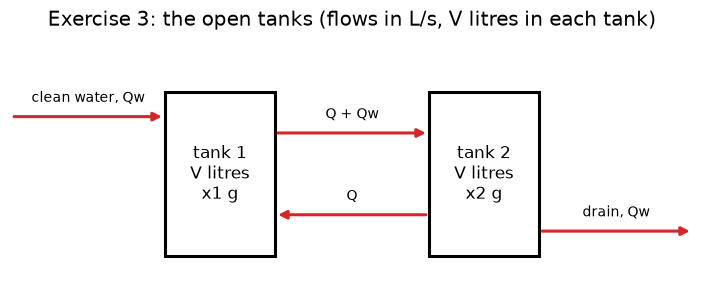

In [16]:
OPEN_FIGURE = (8.0, 2.8)
fig, ax = plt.subplots(figsize=OPEN_FIGURE)
draw_tanks(ax, [("clean", 1, "clean water, Qw"), (1, 2, "Q + Qw"), (2, 1, "Q"), (2, "drain", "drain, Qw")],
           "Exercise 3: the open tanks (flows in L/s, V litres in each tank)")
plt.show()

*The plot shows* the four pipes: clean water into tank 1, $Q + Q_w$ from tank 1 to tank 2, $Q$ back,
$Q_w$ from tank 2 to the drain.

Complete `tank_matrix(Q, Qw, V)`, the matrix $A$ of $\vec{x}\,' = A\vec{x}$ for these tanks. First step: write
$x_1'$ and $x_2'$ as in Section 4 (salt in $-$ salt out; clean water carries no salt; a pipe carries flow
$\times$ the concentration of the tank it leaves); then read the matrix off, row by row, and return it as
`np.array([[..., ...], [..., ...]])`, like `closed_tanks` in Section 4. The next cell computes "salt in
$-$ salt out" of each tank from the list of pipes and compares it with `tank_matrix(Q, Qw, V) @ x`, for
several amounts of salt and three sets of pipes. When your matrix is right, it draws the salt in both
tanks for $V = 100$ L, $Q = 1$ L/s, $Q_w = 3$ L/s, $\vec{x}(0) = (20, 0)$ g: tank 2 first gains salt, then
everything is washed out.

In [17]:
def tank_matrix(Q, Qw, V):
    return None                 # replace None with the formula

In [18]:
PIPE_SETS = ((1.0, 3.0, 100.0), (2.0, 0.5, 40.0), (0.3, 0.0, 10.0))     # Q (L/s), Qw (L/s), V (L)
STATES = ((20.0, 0.0), (0.0, 5.0), (3.0, 7.0))                           # x1, x2 (g)
OPEN_TANKS = PIPE_SETS[0]                                                # the tanks of the figure
T_OPEN = 150.0                                                           # s
PEAK_STEP = 0.01                                                         # s: the grid that finds the peak
BALANCE_TOLERANCE = 1e-9


def pipes_of(Q, Qw):
    # (source, target, flow in L/s): the pipes of the convention
    return (("clean", 1, Qw), (1, 2, Q + Qw), (2, 1, Q), (2, "drain", Qw))


def salt_balance(Q, Qw, V, x):
    # salt in - salt out of each tank (g/s); a pipe carries flow times the concentration where it starts
    rates = {1: 0.0, 2: 0.0}
    for source, target, flow in pipes_of(Q, Qw):
        carried = 0.0 if source == "clean" else flow * x[source - 1] / V
        rates[target] = rates.get(target, 0.0) + carried
        rates[source] = rates.get(source, 0.0) - carried
    return np.array([rates[1], rates[2]])


try:
    matrices = [tank_matrix(*pipes) for pipes in PIPE_SETS]
    if matrices[0] is not None:
        matrices = [np.asarray(matrix, dtype=float) for matrix in matrices]
        if any(matrix.shape != (2, 2) for matrix in matrices):
            matrices = ["not a 2 x 2 matrix"]
except Exception as problem:                               # whatever goes wrong inside the function
    matrices = [f"{type(problem).__name__}: {problem}"]
if matrices[0] is None:
    print("Exercise 3: complete tank_matrix first")
elif isinstance(matrices[0], str):
    print(f"Exercise 3: not yet (tank_matrix must return a 2 x 2 matrix computed from Q, Qw and V; "
          f"got: {matrices[0]})")
else:
    mismatch = None
    for (Q, Qw, V), matrix in zip(PIPE_SETS, matrices):
        for x in STATES:
            balance = salt_balance(Q, Qw, V, x)
            with np.errstate(all="ignore"):
                gap = matrix @ x - balance
            tank = int(np.argmax(np.where(np.isnan(gap), np.inf, np.abs(gap))))
            # "not <=" so that a NaN counts as a mismatch
            if mismatch is None and not abs(gap[tank]) <= BALANCE_TOLERANCE * max(1.0, abs(balance[tank])):
                mismatch = (Q, Qw, V, x, tank, balance[tank], (matrix @ x)[tank])
    if mismatch is not None:
        Q, Qw, V, x, tank, wanted, got = mismatch
        print(f"Exercise 3: not yet. For Q = {Q:g} L/s, Qw = {Qw:g} L/s, V = {V:g} L "
              f"and x = ({x[0]:g}, {x[1]:g}) g, salt in - salt out of tank {tank + 1} is {wanted:.4g} g/s; "
              f"your matrix gives {got:.4g} g/s")
    else:
        print(f"Exercise 3: correct on all {len(PIPE_SETS)} sets of pipes")
        closed = np.asarray(tank_matrix(Q_PUMP, 0.0, V_TANK), dtype=float)
        print("With Qw = 0 each column adds up to", closed.sum(axis=0) + 0.0, ": the total salt stays")
        open_matrix = np.asarray(tank_matrix(*OPEN_TANKS), dtype=float)
        open_case = ol.two_by_two_case(open_matrix)
        times_open = np.linspace(0.0, T_OPEN, N_POINTS)
        salt_open = ol.eigen_solution(times_open, open_matrix, SALT_START)
        fine = np.arange(0.0, T_OPEN, PEAK_STEP)
        tank_2 = ol.eigen_solution(fine, open_matrix, SALT_START)[:, 1]
        peak = int(np.argmax(tank_2))
        directions = [np.round(vector / vector[0], 6).tolist() for vector in open_case.eigenvectors]
        print(f"The open tanks: eigenvalues {open_case.eigenvalues[0]:g} and {open_case.eigenvalues[1]:g} "
              f"per second, eigenvectors {directions[0]} and {directions[1]}; tank 2 holds at most "
              f"{tank_2[peak]:.2f} g, at t = {fine[peak]:.1f} s")
        Q, Qw, V = OPEN_TANKS
        plot = tanks_figure([("clean", 1, f"clean water\nQw = {Qw:g} L/s"),
                             (1, 2, f"Q + Qw = {Q + Qw:g} L/s"),
                             (2, 1, f"Q = {Q:g} L/s"), (2, "drain", f"drain\nQw = {Qw:g} L/s")],
                            f"open tanks, V = {V:g} L each")
        plot.plot(times_open, salt_open[:, 0], "-", linewidth=2, label="x1, tank 1")
        plot.plot(times_open, salt_open[:, 1], "--", linewidth=2, label="x2, tank 2")
        plot.set_title("eigen_solution with your tank_matrix")
        plot.legend(loc="upper right")
        plt.tight_layout()
        plt.show()

Exercise 3: complete tank_matrix first


### Exercise 4 - Explore

* (i) With the slider of Section 7, find the two starts that excite one mode only. Then write $x_1$
  and $x_2$ for each without the slider.
* (ii) *(Lebl, Exercise 3.8.14)* $A = \begin{pmatrix} 3 & -1 \\ 1 & 1 \end{pmatrix} = 2I + B$, $B = A - 2I$.
  Check that $B^2 = 0$; since $2I$ commutes with $B$ ($2I\,B = B\,2I$), $e^{tA} = e^{2t}e^{tB}$, and the
  series $e^{tB} = I + tB + \dots$ stops: $e^{tA} = e^{2t}(I + tB)$ (as in Lebl's simple case, where
  $\begin{pmatrix} 5 & 4 \\ -1 & 1 \end{pmatrix} - 3I$ squares to 0, checked in the code of Section 6). Find
  $e^{tA}$ and the solution with $\vec{x}(0) = (1, 2)$; compare with `expm` and with `ol.eigen_solution`.
* (iii) *(Lebl, Exercise 3.7.10)* $A = \begin{pmatrix} 2 & 0 & 0 \\ -1 & -1 & 9 \\ 0 & -1 & 5 \end{pmatrix}$
  has the eigenvalue 2 three times and defect 2 (two eigenvectors missing). Starting from
  $\vec{w}_3 = (1, 0, 0)$, compute $\vec{w}_2 = (A - 2I)\vec{w}_3$ and $\vec{v} = (A - 2I)\vec{w}_2$; check
  that $(A - 2I)\vec{v} = \vec{0}$.
* (iv) *(Lebl, Example 3.6.2)* Two rail cars joined by a spring: the matrix
  $\begin{pmatrix} -1 & 1 \\ 2 & -2 \end{pmatrix}$ has the eigenvalue 0, and the book finds
  $x_2 = 2t - \tfrac{2}{\sqrt3}\sin(\sqrt3\,t)$ (metres from where car 2 was when the cars linked at
  $t = 0$, **positive towards the wall**, as in the book: the opposite of Section 7's direction). When
  does car 2 reach the wall, 10 m away, and how fast is it going? Solve $x_2(t) = 10$ with `brentq`
  (`from scipy.optimize import brentq`, as in notebooks 10 and 12) between 0 and 10 s; the speed is
  $x_2'(t)$.
* (v) *(Lebl, Example 3.1.6, the way back)* $x' = 2y - x$, $y' = x$, $x(0) = 1$, $y(0) = 0$ (here the
  unknowns are $x(t)$, $y(t)$, the independent variable $t$).
  Differentiate the second equation to get one equation of order 2 for $y$ ($y(0) = 0$ and
  $y'(0) = x(0) = 1$, since $y' = x$); solve it, then find $x$. Compare $x(2)$ and $y(2)$ with the values
  printed in the book, 2.475 and 2.457 (`ol.eigen_solution(2.0, [[-1, 2], [1, 0]], [1, 0])`).
* (vi) *(Lebl, Example 3.4.4)* Check by substitution with SymPy that
  $C_1(1, -1, 0)e^{t} + C_2(0, 1, -1)e^{2t} + C_3(1, 1, 0)e^{3t}$ solves $\vec{x}\,' = A\vec{x}$ for the
  $3 \times 3$ matrix of Section 2 (`REFRESHER`), as the checks of Section 6: `sp.symbols`, `.diff(t)`,
  `sp.simplify`.

In [19]:
# your code here: for example
# expm(0.5 * np.array([[3.0, -1.0], [1.0, 1.0]]))

## 9. Answers

Final answers only; full solutions are given after the sessions.

<details>
<summary>Click to open (after trying)</summary>

1. (a) `[3, -3, 9]`. (b) 4. (c) `[-3, 2, 4]`: a triangular matrix shows its eigenvalues on the
   diagonal. (d) False: if $x_2 = 0$ all the time, then $x_2'' = 0 = x_1 - x_2$, so $x_1 = 0$ too.
2. (a) `[2, 5]`; eigenvectors along $(1, -1)$ and $(1, 2)$. (b) `1 + 2j`; along $(i, 1)$ (for example
   `[1j, 1]`); $x_1 = e^{t}\cos 2t$, $x_2 = e^{t}\sin 2t$. (c) 2; $\vec{v}$ along $(1, 1)$; for
   $\vec{v} = (1, 1)$, $\vec{w} = (1/3, 0)$ or $(0, -1/3)$, or any $\vec{w}$ with $3w_1 - 3w_2 = 1$.
   (d) $x_2 = \tfrac25\cos(t/\sqrt6) - \tfrac25\cos t$ (in m, > 0 away from the wall).
3. `return np.array([[-(Q + Qw), Q], [Q + Qw, -(Q + Qw)]]) / V`. Eigenvalues $-0.06$ and $-0.02$ per
   second, eigenvectors $(1, -2)$ and $(1, 2)$; tank 2 holds at most 7.70 g, at
   $t = 50\ln\sqrt3 = 27.5$ s, the moment when both tanks hold the same amount
   ($x_2' = (Q + Q_w)(x_1 - x_2)/V = 0$); then all the salt is washed out.
4. (i) $x_2(0) = 2$: $(\cos t, 2\cos t)$; $x_2(0) = -1$: $(\cos 2t, -\cos 2t)$. (ii)
   $e^{tA} = e^{2t}\begin{pmatrix} 1 + t & -t \\ t & 1 - t \end{pmatrix}$,
   $\vec{x} = \big((1 - t)e^{2t},\ (2 - t)e^{2t}\big)$. (iii) $\vec{w}_2 = (0, -1, 0)$, $\vec{v} = (0, 3, 1)$,
   the book's vectors. (iv) After 5.22 s, at 3.85 m/s towards the wall (the book's values).
   (v) $y'' + y' - 2y = 0$;
   $x = (e^{t} + 2e^{-2t})/3$, $y = (e^{t} - e^{-2t})/3$; $x(2) = 2.47523$, $y(2) = 2.45691$. (vi) The
   difference between the two sides simplifies to zero.

</details>

**Where to go next:** notebook 18, the pictures of $2 \times 2$ systems in the plane (Lebl 3.5) and
nonlinear systems. Systems with a forcing term are in Lebl, Section 3.9.